In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('Churn_Modelling.csv')

df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


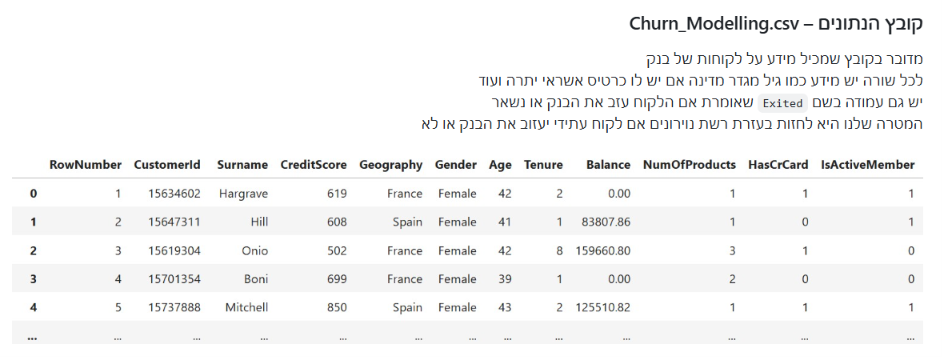

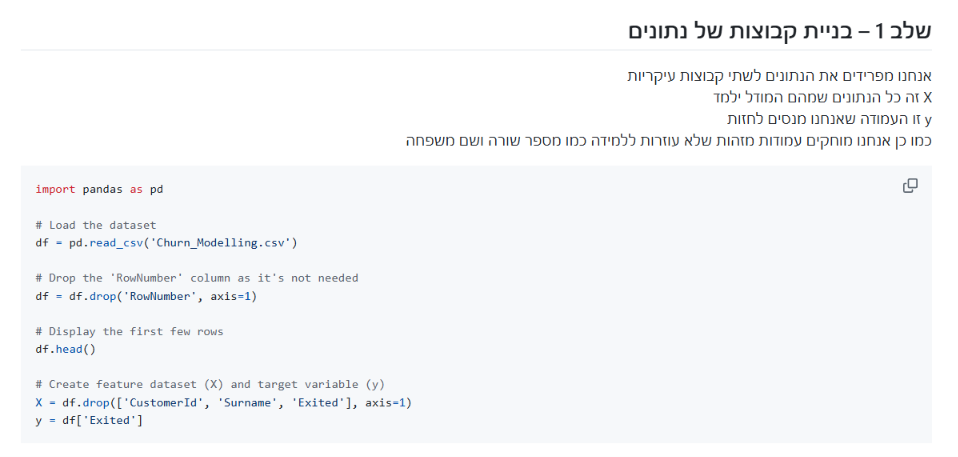

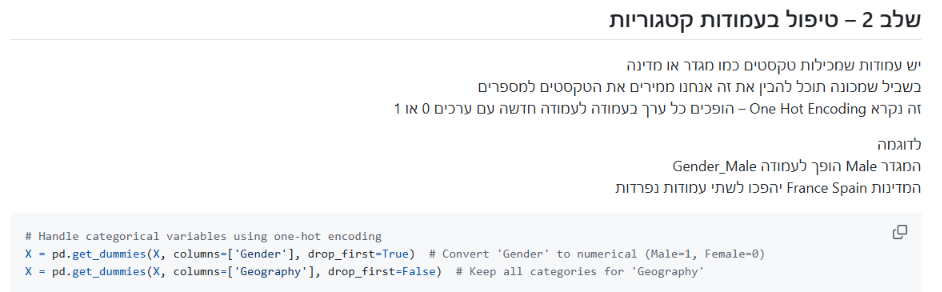

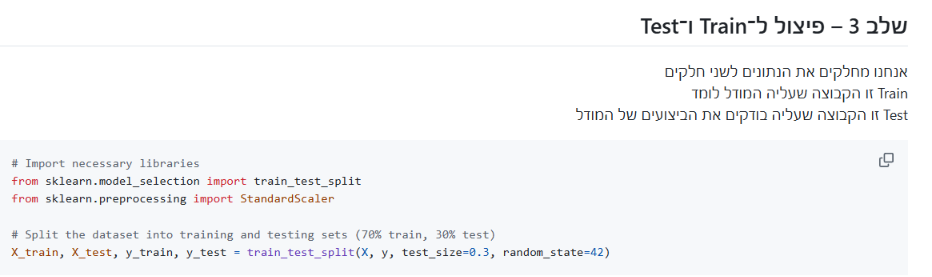

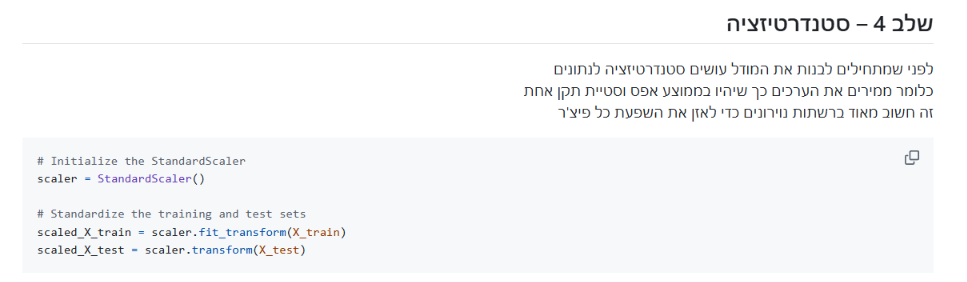

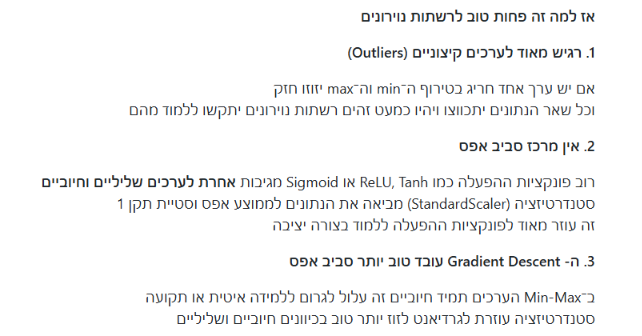

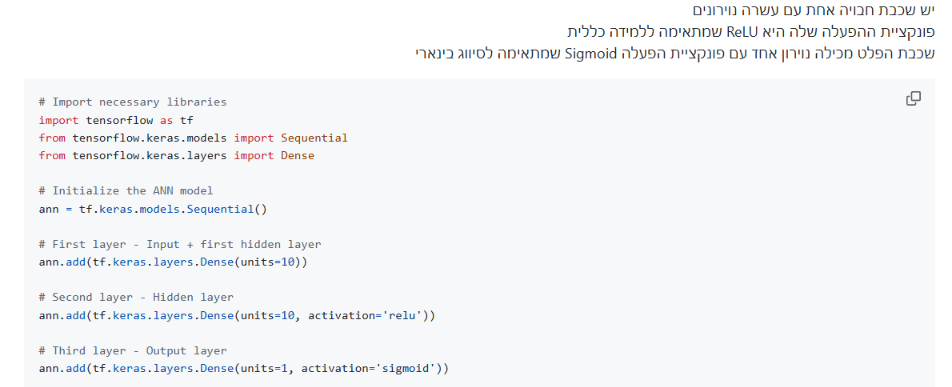

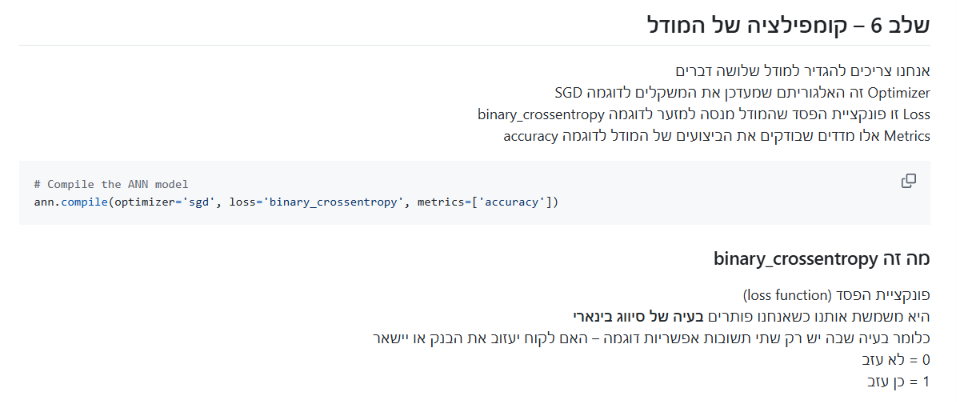

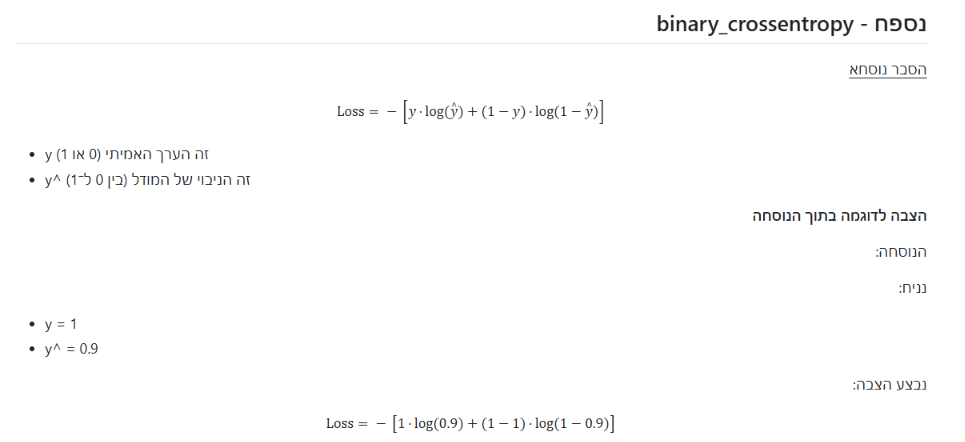

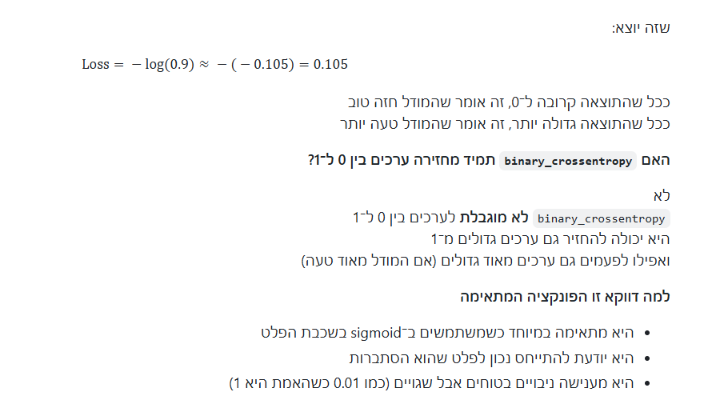

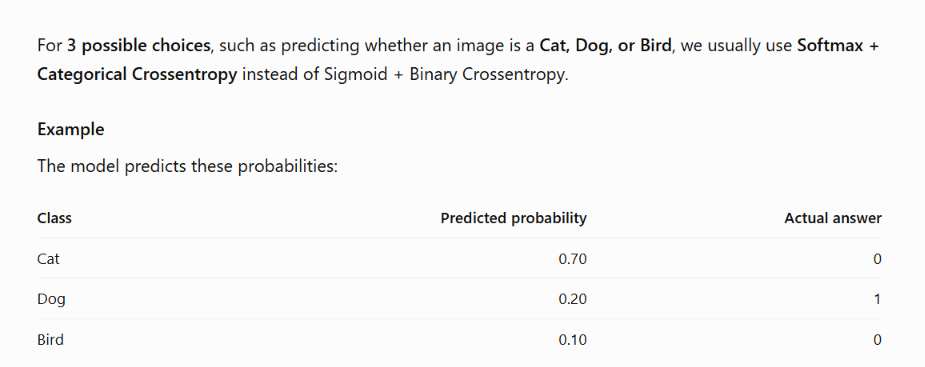

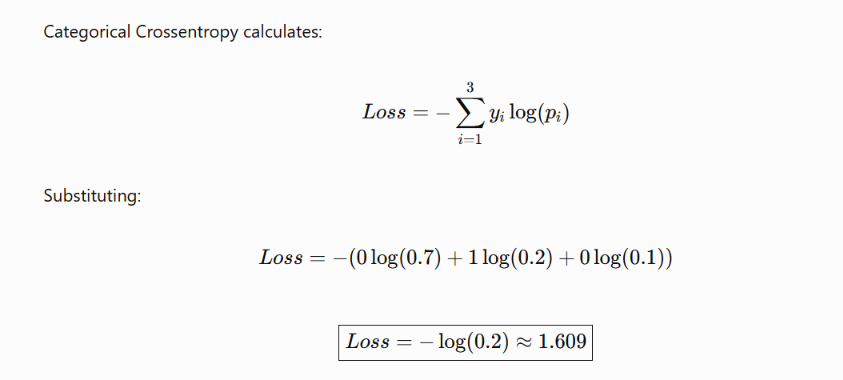

In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv('Churn_Modelling.csv')

# Drop the 'RowNumber' column as it's not needed
df = df.drop('RowNumber', axis=1)

# Display the first few rows
df.head()

# Create feature dataset (X) and target variable (y)
X = df.drop(['CustomerId', 'Surname', 'Exited'], axis=1)
y = df['Exited']

# Handle categorical variables using one-hot encoding
X = pd.get_dummies(X, columns=['Gender'], drop_first=True)  # Convert 'Gender' to numerical (Male=1, Female=0)
X = pd.get_dummies(X, columns=['Geography'], drop_first=False)  # Keep all categories for 'Geography'
print(X.head())

# Import necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize the StandardScaler
scaler = StandardScaler()

# Standardize the training and test sets
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

# Import necessary libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Initialize the ANN model
ann = tf.keras.models.Sequential()

# First layer - Input + first hidden layer
# shape of the input is (7000, 12)
ann.add(tf.keras.layers.Dense(units=10, activation='relu', input_shape=(12,)))

# Second layer - Hidden layer
ann.add(tf.keras.layers.Dense(units=10, activation='relu'))

# Third layer - Output layer
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

# Compile the ANN model
ann.compile(optimizer='sgd', loss='binary_crossentropy', metrics=['accuracy'])

# Train the ANN model
ann.fit(scaled_X_train, y_train, batch_size=32, epochs=100, verbose=1)

# Import necessary libraries
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict on the test set
y_pred = (ann.predict(scaled_X_test) > 0.5)

# Print evaluation metrics
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

# Predicting on new customer data
new_customer_details = [[600, 40, 3, 60000, 2, 1, 1, 50000, 1, 1, 0, 0]]

# Scale the new data
scaled_customer_details = scaler.transform(new_customer_details)

# Predict whether the customer will exit (1) or stay (0)
print(ann.predict(scaled_customer_details) > 0.5)

   CreditScore  Age  Tenure    Balance  NumOfProducts  HasCrCard  \
0          619   42       2       0.00              1          1   
1          608   41       1   83807.86              1          0   
2          502   42       8  159660.80              3          1   
3          699   39       1       0.00              2          0   
4          850   43       2  125510.82              1          1   

   IsActiveMember  EstimatedSalary  Gender_Male  Geography_France  \
0               1        101348.88        False              True   
1               1        112542.58        False             False   
2               0        113931.57        False              True   
3               0         93826.63        False              True   
4               1         79084.10        False             False   

   Geography_Germany  Geography_Spain  
0              False            False  
1              False             True  
2              False            False  
3              F

C:\Users\User\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5559 - loss: 0.7173
Epoch 2/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7924 - loss: 0.5542
Epoch 3/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7924 - loss: 0.5258
Epoch 4/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7924 - loss: 0.5154
Epoch 5/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7924 - loss: 0.5095
Epoch 6/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7924 - loss: 0.5044
Epoch 7/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7924 - loss: 0.4984
Epoch 8/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7924 - loss: 0.4899
Epoch 9/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7930 - loss: 0.4796
Epoch 10/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7954 - loss: 0.4687
Epoch 11/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7997 - loss: 0.4579
Epoch 12/100
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


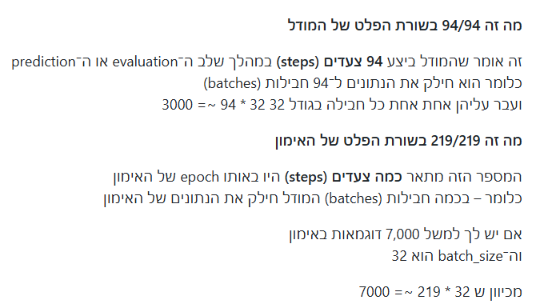

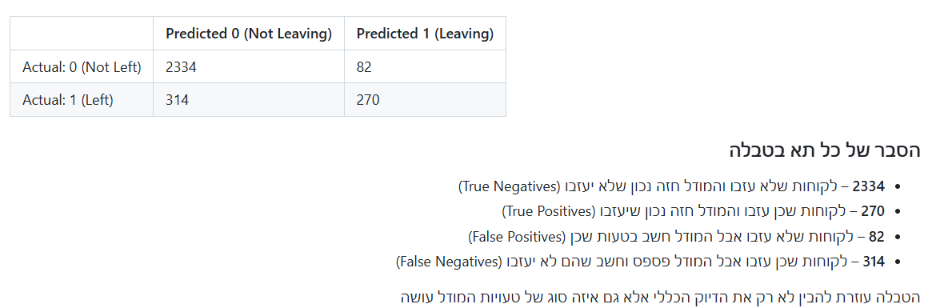

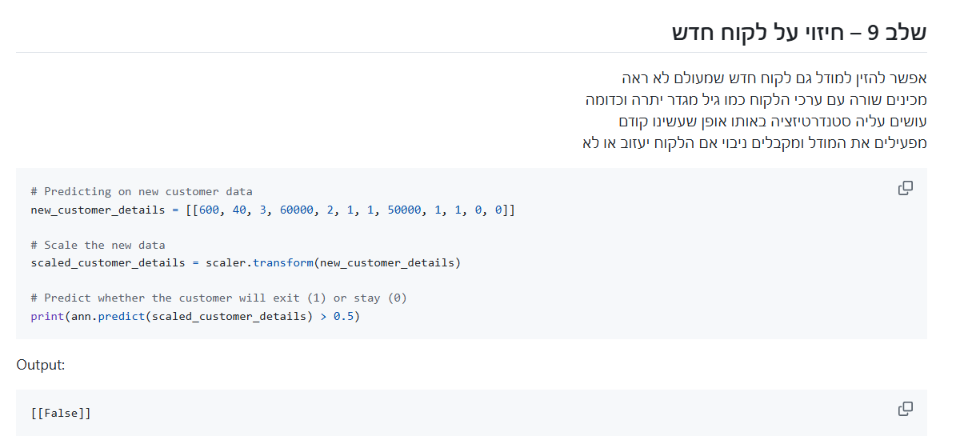

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load and clean the dataset
df = pd.read_csv('Churn_Modelling.csv')
df = df.drop('RowNumber', axis=1)

# 2. Create feature dataset (X) and target variable (y)
X = df.drop(['CustomerId', 'Surname', 'Exited'], axis=1)
y = df['Exited']

# 3. Handle categorical variables using one-hot encoding
X = pd.get_dummies(X, columns=['Gender'], drop_first=True)     # Male=1, Female=0
X = pd.get_dummies(X, columns=['Geography'], drop_first=False) # Keep all categories

# 4. Split into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 5. Standardize the features
scaler = StandardScaler()
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

# 6. Initialize and train the Logistic Regression model
# Using a higher max_iter ensures the optimization algorithm converges properly
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(scaled_X_train, y_train)

# 7. Predict on the test set
y_pred = log_reg.predict(scaled_X_test)

# 8. Print evaluation metrics
print("Accuracy Score:")
print(accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 9. Predicting on new customer data
new_customer_details = [[600, 40, 3, 60000, 2, 1, 1, 50000, 1, 1, 0, 0]]
scaled_customer_details = scaler.transform(new_customer_details)

# Predict whether the customer will exit (1) or stay (0)
print("\nNew Customer Prediction (1 = Exit, 0 = Stay):")
print(log_reg.predict(scaled_customer_details))


Accuracy Score:
0.8113333333333334

Confusion Matrix:
[[2318   98]
 [ 468  116]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.96      0.89      2416
           1       0.54      0.20      0.29       584

    accuracy                           0.81      3000
   macro avg       0.69      0.58      0.59      3000
weighted avg       0.78      0.81      0.77      3000


New Customer Prediction (1 = Exit, 0 = Stay):
[0]


C:\Users\User\anaconda3\Lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
